# 小売のアンケート調査を partworth で分析する

あるスーパーが、自社ブランド（PB）のドリップコーヒーを発売しようとしています。
発売の前に、マーケティング担当者は次の4つを知りたいと考えています。

1. 買い物客は、ブランド・焙煎・有機表示・価格のうち何を重視するか
2. メーカー品2つと並べたとき、何割の買い物客が自社ブランドを選ぶか
3. 利益が最も大きくなる価格はいくらか
4. 有機表示は、追加の原価に見合うか

これに答えるために、商品を選んでもらう形式のアンケート（選択型コンジョイント）を行います。
このノートブックでは、その分析を [partworth](https://github.com/kojikojikojikoji/partworth) で順に進めます。

このノートブックのデータは、すべてダミーデータです。手順1で乱数から作ります。
実在の調査・企業・商品は使っていません。
グラフと表の見出し、水準の名前は英語のままです。

英語版は [retail_survey.ipynb](retail_survey.ipynb) にあります。

## 準備

partworth はまだ PyPI にありません。GitHub からインストールします。グラフには matplotlib を使います。

```
pip install "partworth[nutpie] @ git+https://github.com/kojikojikojikoji/partworth" "matplotlib>=3.10"
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import partworth as pw

## 1. アンケートの内容

400人の買い物客が、1人あたり10問に答えます。1問ごとにコーヒー3商品と「どれも買わない」を見せ、
買い物客は1つを選びます。

商品は4つの属性で表します。

| 属性 | 水準 |
|---|---|
| `brand`（ブランド） | `store_brand`（自社ブランド）, `maker_a`（メーカーA）, `maker_b`（メーカーB） |
| `roast`（焙煎） | `light`（浅煎り）, `medium`（中煎り）, `dark`（深煎り） |
| `organic`（有機表示） | `no`（なし）, `yes`（あり） |
| `price`（価格） | 10袋入りで 398・498・598・698 円のいずれか |

あわせて、店のポイントアプリの会員かどうか（`member`）も聞きます。

次のセルでダミーの回答を作ります。ダミーの買い物客は1人ずつ好みが違います。
たとえば、深煎りが好きな人もいれば、価格をとても気にする人もいます。
アプリ会員は、自社ブランドを少しだけ好むように作っています。
実際の調査では、このセルの代わりに自分のファイルを読み込みます。

In [2]:
rng = np.random.default_rng(7)
N, T, J = 400, 10, 3                       # 買い物客の人数、設問数、1問あたりの商品数
levels = {
    "brand": ["store_brand", "maker_a", "maker_b"],
    "roast": ["light", "medium", "dark"],
    "organic": ["no", "yes"],
}
prices = [398, 498, 598, 698]
member = rng.random(N) < 0.4               # 4割がアプリ会員

# 買い物客ごとの好み。行が買い物客、列が水準。
taste = {
    "brand": np.column_stack([rng.normal(0.6 * member, 0.9),
                              rng.normal(0.5, 0.9, N),
                              rng.normal(0.2, 0.9, N)]),
    "roast": np.column_stack([rng.normal(0.0, 0.7, N),
                              rng.normal(0.4, 0.7, N),
                              rng.normal(0.1, 0.7, N)]),
    "organic": np.column_stack([np.zeros(N), rng.normal(0.5, 0.8, N)]),
}
per_100_yen = -np.exp(rng.normal(np.log(0.8), 0.4, N))   # 100円高くなることを、その人がどれだけ嫌うか
no_purchase = rng.normal(0.3, 0.8, N)                    # 「どれも買わない」の選ばれやすさ

# 各設問に商品をランダムに並べ、買い物客に選ばせる。
picks = {a: rng.integers(len(v), size=(N, T, J)) for a, v in levels.items()}
price = rng.choice(prices, size=(N, T, J))
who = np.arange(N)[:, None, None]
utility = sum(taste[a][who, picks[a]] for a in levels)
utility = utility + per_100_yen[:, None, None] * (price - 548) / 100
utility = np.concatenate(
    [utility, np.broadcast_to(no_purchase[:, None, None], (N, T, 1))], axis=2)
choice = (utility + rng.gumbel(size=utility.shape)).argmax(axis=2)   # 0〜2: 商品、3: どれも買わない

# 回答を縦長の表にする。1行が「買い物客 × 設問 × 選択肢」。
i, t, j = np.meshgrid(np.arange(N), np.arange(T), np.arange(J), indexing="ij")
products = pd.DataFrame({
    "respondent": i.ravel() + 1, "question": t.ravel() + 1, "option": j.ravel() + 1,
    **{a: np.array(v)[picks[a].ravel()] for a, v in levels.items()},
    "price": price.ravel(), "no_purchase": False,
})
i, t = np.meshgrid(np.arange(N), np.arange(T), indexing="ij")
nones = pd.DataFrame({"respondent": i.ravel() + 1, "question": t.ravel() + 1,
                      "option": J + 1, "no_purchase": True})
survey = pd.concat([products, nones]).sort_values(
    ["respondent", "question", "option"], ignore_index=True)
picked = choice[survey["respondent"] - 1, survey["question"] - 1] + 1
survey["chosen"] = (survey["option"] == picked).astype(int)
survey["price"] = survey["price"].astype("Int64")        # 円は整数。「どれも買わない」の行は空欄

shoppers = pd.DataFrame({"member": np.where(member, "yes", "no")},
                        index=pd.Index(np.arange(1, N + 1), name="respondent"))

1人目の買い物客の1問目です。選択肢1〜3が商品、選択肢4が「どれも買わない」です。
`chosen` は、選んだ選択肢で1になります。

In [3]:
survey.head(4)

,respondent,question,option,brand,roast,organic,price,no_purchase,chosen
0,1,1,1,maker_b,medium,yes,698,False,0
1,1,1,2,store_brand,dark,no,698,False,0
2,1,1,3,store_brand,medium,yes,498,False,0
3,1,1,4,NaN,NaN,NaN,<NA>,True,1


## 2. データを読み込んで確認する

`ChoiceData.from_long` は、縦長の表を読み込んで確認します。たとえば、どの設問でも選ばれた選択肢が
ちょうど1つであることを確かめます。

- `pw.Categorical` は、水準に名前がある属性に使います。
- `pw.Linear(sign="negative")` は、価格を数値として扱います。あわせて、価格が上がって商品の魅力が
  増すことはない、とモデルに伝えます。
- `covariates` には、買い物客ごとの情報を渡します。ここではアプリ会員かどうかです。

In [4]:
data = pw.ChoiceData.from_long(
    survey,
    attributes={
        "brand": pw.Categorical(levels["brand"]),
        "roast": pw.Categorical(levels["roast"]),
        "organic": pw.Categorical(levels["organic"]),
        "price": pw.Linear(sign="negative"),
    },
    respondent="respondent", task="question", alternative="option", chosen="chosen",
    none="no_purchase",
    covariates=shoppers,
)
data

ChoiceData(respondents=400, max_tasks=10, max_alternatives=4, params=7, covariates=1)

`describe()` は、各水準が何回提示され、何回選ばれたかを数えます。モデルを推定する前に確認します。
提示回数が少ない水準は、うまく推定できません。

この集計だけでも傾向が分かります。398円の商品は、698円の商品の約4倍選ばれています。

In [5]:
data.describe().round(3)

,attribute,level,shown,chosen,rate
0,brand,store_brand,4027,1032,0.256
1,brand,maker_a,3967,1156,0.291
2,brand,maker_b,4006,1055,0.263
3,roast,light,3902,961,0.246
4,roast,medium,4014,1230,0.306
5,roast,dark,4084,1052,0.258
6,organic,no,5986,1378,0.230
7,organic,yes,6014,1865,0.310
8,price,398,2881,1357,0.471
9,price,498,3027,956,0.316


## 3. モデルを推定する

モデルは階層ベイズの多項ロジットです。かんたんに言うと、買い物客1人ずつに好みの値を推定します。
1人あたり10問では回答が少ないので、ほかの買い物客から分かる傾向も使います。

結果を見る前に、必ず診断を読みます。診断は、推定が収束したかどうかと、収束しなかったときに
試すことを示します。この推定は、ノートパソコンで1分ほどかかります。

診断の最後の数行は、好みどうしの相関についての行です。相関を安定して推定するには、MCMC の
サンプル数（`draws`）をほかの結果より多くする必要があります。このノートブックでは相関を報告しないので、このまま進めます。

In [6]:
result = pw.HierarchicalMNL(data).fit(draws=2000, tune=3000, chains=4, random_seed=1)
print(result.diagnostics().report())

converged
R-hat max      1.006  (target < 1.01)
ESS bulk min   1380  (target > 400)
ESS tail min   1736  (target > 400)
divergences    0  (target 0)
worst variable tau
correlations   R-hat max 1.013, ESS bulk min 597
what to try:
- correlations have not reached the targets: part-worths, shares and WTP are unaffected, but rerun with more draws (e.g. 3000) before reporting correlations


## 4. 買い物客は何を重視するか

`importances()` は、買い物客ごとに各属性の重要度（％）を返します。グラフは、中央値と買い物客の間の
ばらつきを示します。下の表は平均です。

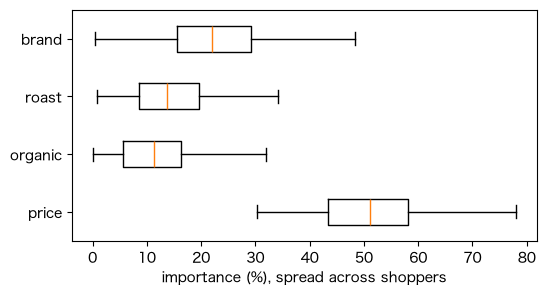

brand      22.7
roast      14.5
organic    11.6
price      51.2
dtype: float64

In [7]:
importance = result.importances()

fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot([importance[a] for a in importance.columns], orientation="horizontal",
           tick_labels=list(importance.columns), showfliers=False)
ax.invert_yaxis()
ax.set_xlabel("importance (%), spread across shoppers")
plt.show()

importance.mean().round(1)

平均では価格が最も重視されています。箱の幅が広いので、買い物客による違いは大きいです。
価格よりブランドを重視する人もいます。

価格の重要度は、調査で提示した価格の幅で変わります。幅を広げれば数値は大きくなります。

`part_worths()` は、水準ごとの好みの強さ（部分効用）を返します。1行が1人の買い物客です。
数値が大きいほど、その水準を好みます。価格の列は、1円あたりの変化です。
NONE の列が大きな負の値なのは、価格0円の商品と比べた値だからです。

In [8]:
result.part_worths().head().round(3)

attribute        brand                  roast               organic         \
level      store_brand maker_a maker_b  light medium   dark      no    yes   
respondent                                                                   
1               -0.746   0.871  -0.125 -0.526  0.609 -0.083   0.224 -0.224   
2               -0.050  -0.260   0.310 -0.517  0.491  0.026  -0.243  0.243   
3               -0.678  -0.285   0.963  0.087 -0.440  0.353  -0.530  0.530   
4                0.549  -0.800   0.251 -0.774  0.680  0.093  -0.263  0.263   
5               -0.610   0.902  -0.292 -0.619  0.397  0.222  -0.031  0.031   

attribute   price   NONE  
level       slope   NONE  
respondent                
1          -0.008 -2.514  
2          -0.012 -6.961  
3          -0.007 -4.656  
4          -0.007 -4.768  
5          -0.009 -4.511

## 5. 売り場ではどの商品が選ばれるか

3つの商品を売り場に並べ、買い物客がどう選ぶかをシミュレーターで計算します。
`shares()` は、各商品が選ばれる割合と、その90%信用区間を返します。

In [9]:
shelf = pd.DataFrame({
    "product": ["Store brand", "Maker A", "Maker B"],
    "brand": ["store_brand", "maker_a", "maker_b"],
    "roast": ["medium", "medium", "dark"],
    "organic": ["no", "no", "yes"],
    "price": [498, 598, 648],
})
sim = pw.MarketSimulator(result)
sim.shares(shelf).round(3)

,product,share,lower,upper
0,Store brand,0.366,0.343,0.388
1,Maker A,0.216,0.198,0.234
2,Maker B,0.209,0.189,0.230
3,NONE,0.209,0.194,0.224


498円なら、100人のうち約37人が自社ブランドを選びます。約21人は何も買いません。

この数字は、アンケートの中で選ばれる割合です。売上の予測ではありません。実際の売上は、
棚の位置・在庫・販促など、アンケートに含まれない要因でも変わります。

## 6. 利益が最も大きくなる価格はいくらか

`price_curve()` は、1つの商品の価格だけを動かし、売り場のほかの商品はそのままにします。

1パックの原価を300円と仮定します。このとき、買い物客100人あたりの利益は
`選ばれる割合 × 100 × (価格 − 300)` です。

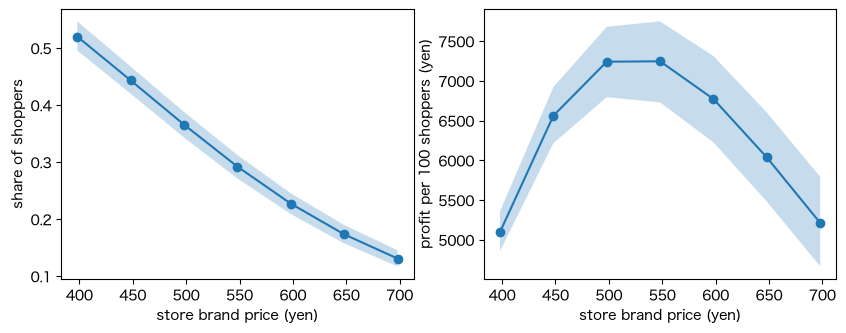

,price,share,lower,upper,profit_share
0,398,0.520,0.496,0.547,5097.695
1,448,0.443,0.420,0.468,6562.136
2,498,0.366,0.343,0.388,7242.475
3,548,0.292,0.271,0.312,7246.970
4,598,0.227,0.209,0.245,6772.295
5,648,0.173,0.157,0.190,6036.629
6,698,0.131,0.117,0.146,5212.435


In [10]:
unit_cost = 300
curve = sim.price_curve(shelf, product="Store brand", grid=list(range(398, 699, 50)))
for col in ["share", "lower", "upper"]:
    curve[f"profit_{col}"] = curve[col] * 100 * (curve["price"] - unit_cost)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
left.plot(curve["price"], curve["share"], marker="o")
left.fill_between(curve["price"], curve["lower"], curve["upper"], alpha=0.25)
left.set_xlabel("store brand price (yen)")
left.set_ylabel("share of shoppers")
right.plot(curve["price"], curve["profit_share"], marker="o")
right.fill_between(curve["price"], curve["profit_lower"], curve["profit_upper"], alpha=0.25)
right.set_xlabel("store brand price (yen)")
right.set_ylabel("profit per 100 shoppers (yen)")
plt.show()

curve[["price", "share", "lower", "upper", "profit_share"]].round(3)

価格を上げると、選ばれる割合は下がります。利益は500〜550円の付近で最も大きくなります。
帯は90%信用区間です。498円と548円の利益はほぼ同じで、100人あたり約7,240円です。
この調査からは2つの価格の優劣を判断できません。

## 7. 有機表示は原価に見合うか

`wtp()` は支払意思額を返します。支払意思額は、有機表示で増える魅力をちょうど打ち消す値上げ幅です。
買い物客の中央値と、その90%信用区間を返します。

In [11]:
organic_wtp = pw.wtp(result, attribute="organic", from_level="no", to_level="yes")
organic_wtp.round(1)

,attribute,from,to,median,lower,upper,mean,share_negative_price_slope
0,organic,no,yes,61.2,49.5,73.4,66.9,1.0


支払意思額の中央値は約60円です。買い物客の半数は、有機表示に60円以上多く支払ってもよいと
考えています。有機表示で増える1パックあたりの原価がこれより小さければ、検討する価値があります。

シミュレーターで具体的な案を試せます。ここでは、自社ブランドに有機表示を付け、価格を50円上げます。

In [12]:
organic_shelf = shelf.copy()
organic_shelf.loc[0, ["organic", "price"]] = ["yes", 548]

pd.concat({"plain at 498 yen": sim.shares(shelf).set_index("product"),
           "organic at 548 yen": sim.shares(organic_shelf).set_index("product")},
          axis=1).round(3)

plain at 498 yen               organic at 548 yen              
                       share  lower  upper              share  lower  upper
product                                                                    
Store brand            0.366  0.343  0.388              0.387  0.366  0.407
Maker A                0.216  0.198  0.234              0.210  0.190  0.229
Maker B                0.209  0.189  0.230              0.185  0.168  0.205
NONE                   0.209  0.194  0.224              0.218  0.202  0.234

有機表示を付けて548円にすると、自社ブランドが選ばれる割合は約37%から約39%になります。
増え方は小さいです。1パックあたりの売価も50円上がります。

2つの案は同じ事後サンプルから計算するので、信用区間の重なりからは差の有無を判断できません。

有機表示で増える原価が50円をはっきり下回るなら、この案は採算が合います。

## 8. アプリ会員は選び方が違うか

`weights` を使うと、シミュレーションの対象を一部の買い物客に絞れます。重み1の買い物客を残し、
重み0の買い物客を除きます。

In [13]:
is_member = (shoppers["member"] == "yes").astype(float)

pd.concat({"app members": sim.shares(shelf, weights=is_member).set_index("product"),
           "other shoppers": sim.shares(shelf, weights=1 - is_member).set_index("product")},
          axis=1).round(3)

app members               other shoppers              
                  share  lower  upper          share  lower  upper
product                                                           
Store brand       0.415  0.380  0.451          0.333  0.305  0.359
Maker A           0.211  0.184  0.238          0.219  0.199  0.241
Maker B           0.185  0.154  0.215          0.226  0.200  0.253
NONE              0.190  0.169  0.213          0.222  0.203  0.242

アプリ会員のほうが、自社ブランドを選ぶ割合が高くなっています。発売の告知は、アプリから始めるのが
自然です。

## 9. 正解と比べる

ダミーデータでは、買い物客1人ずつの真の好みが分かっています。そのため、推定値を確かめられます。
実際の調査には正解がありません。そのときは、手順3の診断と、推定に使わない設問での確認
（ホールドアウト、`data.holdout(...)`）を使います。

In [14]:
true_wtp = np.median(taste["organic"][:, 1] / -per_100_yen * 100)
print(f"organic label, median willingness to pay: true {true_wtp:.0f} yen, "
      f"estimated {organic_wtp['median'][0]:.0f} yen "
      f"(90% interval {organic_wtp['lower'][0]:.0f} to {organic_wtp['upper'][0]:.0f})")

# 手順5の売り場で各商品が選ばれる割合を、真の好みから計算する。
true_utility = np.column_stack(
    [sum(taste[a][:, levels[a].index(row[a])] for a in levels)
     + per_100_yen * (row["price"] - 548) / 100 for _, row in shelf.iterrows()]
    + [no_purchase])
true_share = np.exp(true_utility) / np.exp(true_utility).sum(axis=1, keepdims=True)
check = sim.shares(shelf).set_index("product")
check.insert(0, "true share", true_share.mean(axis=0))
check.round(3)

organic label, median willingness to pay: true 60 yen, estimated 61 yen (90% interval 49 to 73)


,true share,share,lower,upper
product,,,,
Store brand,0.355,0.366,0.343,0.388
Maker A,0.227,0.216,0.198,0.234
Maker B,0.207,0.209,0.189,0.230
NONE,0.211,0.209,0.194,0.224


真の支払意思額と真の割合は、90%信用区間の中にあります。この例では、買い物客全体についての
結果を再現できています。ただし、これはモデルと同じ仮定で作ったダミーデータ1回分の結果です。
実際の調査では、これほどは合いません。

1人ずつの結果は、それほど正確ではありません。次のグラフは、価格への敏感さについて、
買い物客1人ずつの真の値と推定値を比べます。

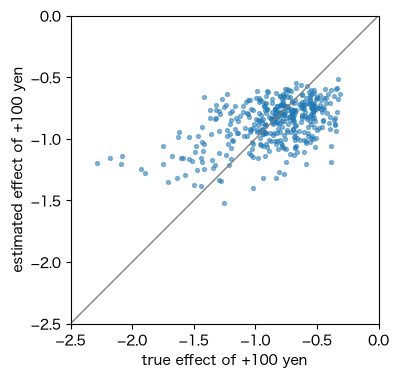

correlation: 0.51


In [15]:
estimated = result.part_worths()[("price", "slope")] * 100

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(per_100_yen, estimated, s=8, alpha=0.5)
ax.axline((-1, -1), slope=1, color="gray", linewidth=1)
ax.set_xlim(-2.5, 0)
ax.set_ylim(-2.5, 0)
ax.set_aspect("equal")
ax.set_xlabel("true effect of +100 yen")
ax.set_ylabel("estimated effect of +100 yen")
plt.show()
print(f"correlation: {np.corrcoef(per_100_yen, estimated)[0, 1]:.2f}")

1つの点が買い物客1人を表します。灰色の線の上にある点は、推定値が真の値と一致しています。
モデルは傾向を捉えています。価格に敏感な買い物客ほど、推定値が低くなっています。
ただし、相関は約0.5にとどまります。1人あたりの回答は10問だけなので、モデルは1人ずつの値を
平均の方向に寄せて推定します。

結果は、手順5〜8のように買い物客の集団について使います。1人の数値を細かく読み取ることは
避けます。

## 10. 結果を保存する

`to_sawtooth_csv()` は、Sawtooth 形式に合わせた列の並びで、買い物客1人を1行として書き出します。
`result.save()` は推定結果の全体を保存します。保存しておけば、あとで推定をやり直さずに
新しいシミュレーションができます。

```python
result.to_sawtooth_csv("retail_utilities.csv")
result.save("retail_fit.nc")
result = pw.HBResult.load("retail_fit.nc", data)
```

## 次に読むもの

- [docs/guide.md](../docs/guide.md)（英語）は、分析の途中で決めることを説明しています。
- [camera.py](camera.py) は、主な手順（推定・選ばれる割合・支払意思額）を公開データで実行します。